In [1]:
!pip install -q -r https://raw.githubusercontent.com/Pascingo/CTA-media-analysis/main/requirements.txt

import os
import re
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import gdown
from tqdm.auto import tqdm
import hashlib
from sentence_transformers import SentenceTransformer
from google.colab import drive

# Same settings as in Stage 1
TEXT_COLUMN = "content"
START_DATE = "2024-09-01"
END_DATE = "2026-08-31"

GOVERNANCE_KEYWORDS = [
    "security", "accountability", "bias", "fairness",
    "regulatory", "regulation", "governance", "policy",
    "ethics", "compliance", "law"
]
MIN_KEYWORD_HITS = 5
RANDOM_STATE = 42

# Folders and files
DATA_FOLDER = "data"

# Stage 3 results are saved on Google Drive, so that caches survive a runtime reset

drive.mount("/content/drive")
STAGE3_FOLDER = "/content/drive/MyDrive/CTA-media-analysis/stage3"
os.makedirs(STAGE3_FOLDER, exist_ok=True)

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/14cAxvtxuTfwENtSDCmGcRpl6qhl-z62z"

DATASET_FILE     = os.path.join(DATA_FOLDER, "ai_media_dataset_20260911.csv")
STAGE1_GOV_FILE  = os.path.join(DATA_FOLDER, "ai_governance_cleaned.csv")
ENTITIES_FILE    = os.path.join(DATA_FOLDER, "entities_spacy.csv")
LANGEXTRACT_FILE = os.path.join(DATA_FOLDER, "langextract_ollama_25pm.jsonl")

Mounted at /content/drive


### Download of the Stage 1 data (Pascal)

We download the files from our public Google Drive folder: the fixed dataset version (2026-09-11), the Stage 1 governance corpus, the spaCy entities and the LangExtract results. The download is skipped if the files are already in the folder `data`.

In [2]:
STAGE1_FILES = [DATASET_FILE, STAGE1_GOV_FILE, ENTITIES_FILE, LANGEXTRACT_FILE]

if not all(os.path.exists(f) for f in STAGE1_FILES):
    gdown.download_folder(DRIVE_FOLDER_URL, output=DATA_FOLDER, quiet=True)

for f in STAGE1_FILES:
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found. Please check the Google Drive folder.")
    print(f"{f:<45} {os.path.getsize(f) / 1e6:>8.1f} MB")

data/ai_media_dataset_20260911.csv               529.7 MB
data/ai_governance_cleaned.csv                   438.6 MB
data/entities_spacy.csv                          220.6 MB
data/langextract_ollama_25pm.jsonl                 2.7 MB


### Reconstructing the Stage 1 corpus with document IDs (Pascal)

In Stage 1 we saved the governance corpus without its index. The spaCy entities and the LangExtract results, however, refer to the articles by this index (`doc_id`). We therefore repeat the cleaning steps of Stage 1 on the original dataset. The steps are deterministic, so we get the same articles with the same `doc_id`.

Two checks make sure this worked:

1. The number of articles and the titles must be identical to `ai_governance_cleaned.csv`.
2. All `doc_id`s in the LangExtract results must exist in the reconstructed corpus.

We keep the **full cleaned corpus** (`df`), and not only the 12,393 Stage 1 articles. The new topic filter in Part 1 has to be evaluated on all articles, so that we also see relevant articles that the Stage 1 filter missed (recall). The column `in_stage1` marks the articles of the Stage 1 corpus.

In [3]:
# 1. Same cleaning as in Stage 1 (sections 2 and 3)
df = pd.read_csv(DATASET_FILE, usecols=["title", "date", "content", "domain", "url", "tags"])
df = df.dropna(subset=[TEXT_COLUMN])
df = df.drop_duplicates(subset=[TEXT_COLUMN])

df["published_at"] = pd.to_datetime(df["date"], errors="coerce")
df = df[(df["published_at"] >= START_DATE) & (df["published_at"] <= END_DATE)].copy()

df["cleaned_text"] = df[TEXT_COLUMN].apply(
    lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()
)
df["cleaned_text"] = (
    df["cleaned_text"]
    .str.lower()
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

pattern = r"\b(?:" + "|".join(GOVERNANCE_KEYWORDS) + r")\b"
df["gov_keyword_hits"] = df["cleaned_text"].str.count(pattern)
df["in_stage1"] = df["gov_keyword_hits"] >= MIN_KEYWORD_HITS
df.index.name = "doc_id"

# 2. Check 1: same articles as the saved Stage 1 corpus
df_gov_s1 = pd.read_csv(STAGE1_GOV_FILE)
stage1_ids = df.index[df["in_stage1"]]

assert len(stage1_ids) == len(df_gov_s1), "Number of articles differs from Stage 1."
assert (
    df.loc[stage1_ids, "title"].fillna("").values == df_gov_s1["title"].fillna("").values
).all(), "Titles differ from Stage 1."

# Take over the columns computed in Stage 1 (spaCy lemmas, sentiment)
for col in ["processed_text", "sentiment_polarity"]:
    df.loc[stage1_ids, col] = df_gov_s1[col].values

# 3. Check 2: the LangExtract results refer to existing articles
lx_doc_ids = pd.read_json(LANGEXTRACT_FILE, lines=True)["doc_id"]
share_found = lx_doc_ids.isin(stage1_ids).mean()
assert share_found == 1.0, f"Only {share_found:.1%} of the LangExtract doc_ids were found."

print(f"Full cleaned corpus:        {len(df):>6,} articles")
print(f"Stage 1 governance corpus:  {df['in_stage1'].sum():>6,} articles")
print(f"LangExtract articles found: {lx_doc_ids.nunique():>6,} (100%)")

Full cleaned corpus:        47,444 articles
Stage 1 governance corpus:  12,393 articles
LangExtract articles found:    599 (100%)


# 1. Addressing the Stage 1 feedback

The feedback on Stage 1 named three problems:

1. Several topics of our corpus are about **broader politics, energy and enterprise technology** rather than AI Governance. Our topic filter was too broad.
2. The relation extraction produced many **inconsistent predicates** and **source-alignment problems**. After schema filtering, very few factual relations remained.
3. The co-occurrence graph is useful for exploration, but it is **not factual evidence**.

These problems directly affect the RAG system: irrelevant articles become irrelevant retrieved passages, and wrong relations become wrong "facts" in the answers. We therefore address them first.

## 1.1 Tightened topic filter (Pascal)

The Stage 1 filter counted eleven general keywords and kept every article with at least 5 hits. It had two weaknesses:

- **Generic words** such as *security*, *policy* and *law* also appear in articles about cybersecurity products, US domestic politics or company policies.
- **Absolute counts** favour long articles: a 4,000-word article about energy markets reaches 5 hits easily, even if governance is only a side remark.

The new filter works in three steps:

1. **Governance score:** We count specific governance terms in two groups. *Strong terms* (e.g. *AI Act*, *code of practice*, *AI safety institute*, *copyright*, *lawsuit*) are clearly about governance on their own and get weight 3. *Medium terms* (e.g. *regulation*, *accountability*, *bias*, *oversight*) get weight 1. The generic words *security*, *policy* and *law* are no longer counted. We divide the weighted hits by the article length (**hits per 1,000 words**), so that long articles are not favoured.
2. **Off-topic score:** For the three confounders named in the feedback (politics, energy, enterprise technology), we count typical terms in the same way. The term lists are based on our Stage 1 topics 2, 3, 4, 5 and 7.
3. **Decision rule:** An article is kept if governance is dense enough, appears in the title or across several distinct terms, and is **at least as dense as the strongest off-topic vocabulary**. In other words, governance has to be the main subject, not a side remark.

The thresholds in this section are **provisional**. In section 1.2 we evaluate the filter on a manually annotated sample and choose the final thresholds there.

In [4]:
import hashlib

# Strong terms: clearly about AI Governance on their own (weight 3)
STRONG_TERMS = [
    r"ai act", r"code of practice", r"ai (?:safety|security) institutes?",
    r"executive orders?", r"gdpr", r"digital services act", r"responsible ai",
    r"ai governance", r"ai regulations?", r"ai safety", r"ai ethics",
    r"algorithmic bias", r"sb 53", r"sb 1047", r"frontier ai", r"deepfakes?",
    r"copyright", r"lawsuits?", r"data protection", r"ai liability",
    # AI security is part of our track
    r"ai security", r"prompt injections?", r"adversarial attacks?", r"(?:data|model) poisoning",
]

# Medium terms: typical governance vocabulary (weight 1)
MEDIUM_TERMS = [
    r"regulations?", r"regulatory", r"regulators?", r"legislation", r"lawmakers?",
    r"governance", r"accountability", r"fairness", r"bias(?:es|ed)?", r"discrimination",
    r"ethic(?:s|al)", r"transparency", r"oversight", r"liability", r"compliance",
    r"privacy", r"audits?", r"watermark(?:s|ing)?", r"red teaming", r"jailbreaks?",
    r"misinformation", r"ai risks?",
]

# Off-topic vocabulary for the three confounders named in the feedback
OFFTOPIC_TERMS = {
    "politics": [
        r"elections?", r"campaigns?", r"voters?", r"democrats?", r"republicans?",
        r"tariffs?", r"trade war", r"immigration", r"ukraine", r"russia",
        r"israel", r"gaza", r"iran", r"nato", r"military",
    ],
    "energy": [
        r"energy", r"electricity", r"power grids?", r"grid", r"nuclear",
        r"gigawatts?", r"megawatts?", r"utilities", r"oil", r"gas", r"solar",
        r"emissions", r"data centers?",
    ],
    "enterprise": [
        r"revenue", r"earnings", r"quarterly", r"shares", r"stock", r"investors?",
        r"valuation", r"funding round", r"ipo", r"customers?", r"enterprises?",
        r"saas", r"hybrid cloud", r"red hat", r"kubernetes", r"apis?",
        r"developers?", r"workflows?", r"productivity", r"mcp",
    ],
}


def count_terms(texts, terms, desc):
    """Count every term in every text in ONE pass per text.
    Each term is its own capture group; match.lastindex tells us which term matched."""
    regex = re.compile("|".join(rf"(\b{t}\b)" for t in terms))
    counts = np.zeros((len(texts), len(terms)), dtype=np.int32)
    for i, text in enumerate(tqdm(texts, desc=desc)):
        for match in regex.finditer(text):
            counts[i, match.lastindex - 1] += 1
    return pd.DataFrame(counts, columns=terms, index=texts.index)


# Cache: the file name contains a hash of the term lists,
# so the features are recomputed automatically when a list changes
term_hash = hashlib.md5(
    json.dumps([STRONG_TERMS, MEDIUM_TERMS, OFFTOPIC_TERMS]).encode()
).hexdigest()[:8]
TOPIC_FEATURES_FILE = os.path.join(STAGE3_FOLDER, f"topic_features_{term_hash}.parquet")

df["cleaned_title"] = (
    df["title"].fillna("").astype(str).str.lower()
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
)
df["n_words"] = df["cleaned_text"].str.count(" ") + 1

if os.path.exists(TOPIC_FEATURES_FILE):
    features = pd.read_parquet(TOPIC_FEATURES_FILE)
    print("Loaded topic features from cache.")
else:
    strong_counts = count_terms(df["cleaned_text"], STRONG_TERMS, "strong terms")
    medium_counts = count_terms(df["cleaned_text"], MEDIUM_TERMS, "medium terms")

    features = pd.DataFrame(index=df.index)
    features["gov_strong_hits"] = strong_counts.sum(axis=1)
    features["gov_medium_hits"] = medium_counts.sum(axis=1)
    features["gov_distinct_terms"] = (strong_counts > 0).sum(axis=1) + (medium_counts > 0).sum(axis=1)

    title_pattern = "|".join(rf"\b{t}\b" for t in STRONG_TERMS + MEDIUM_TERMS)
    features["gov_in_title"] = df["cleaned_title"].str.contains(title_pattern, regex=True)

    for category, terms in OFFTOPIC_TERMS.items():
        features[f"off_{category}_hits"] = count_terms(df["cleaned_text"], terms, category).sum(axis=1)

    features.to_parquet(TOPIC_FEATURES_FILE)

df = df.drop(columns=features.columns, errors="ignore").join(features)

# Densities per 1,000 words
df["gov_score_per_1k"] = 1000 * (3 * df["gov_strong_hits"] + df["gov_medium_hits"]) / df["n_words"]
for category in OFFTOPIC_TERMS:
    df[f"off_{category}_per_1k"] = 1000 * df[f"off_{category}_hits"] / df["n_words"]

OFF_COLUMNS = [f"off_{c}_per_1k" for c in OFFTOPIC_TERMS]
df["off_max_per_1k"] = df[OFF_COLUMNS].max(axis=1)
df["off_main_category"] = df[OFF_COLUMNS].idxmax(axis=1).str.replace("off_", "").str.replace("_per_1k", "")

df[["n_words", "gov_score_per_1k", "gov_distinct_terms"] + OFF_COLUMNS].describe().round(2)

Loaded topic features from cache.


,n_words,gov_score_per_1k,gov_distinct_terms,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
count,47444.00,47444.00,47444.00,47444.00,47444.00,47444.00
mean,1659.03,3.61,1.92,0.83,1.47,5.95
std,1154.28,7.45,2.50,2.84,5.01,8.03
min,210.00,0.00,0.00,0.00,0.00,0.00
25%,969.00,0.00,0.00,0.00,0.00,0.67
50%,1248.00,1.15,1.00,0.00,0.00,2.98
75%,1853.00,3.80,3.00,0.00,0.84,8.15
max,9533.00,129.73,28.00,61.77,96.92,80.00


### Lexical candidate filter (Pascal)

A first run showed that the lexical score alone is not precise enough. Articles about healthcare, construction, solar panels or tax reached a governance score of 5–9 only through general words such as *privacy*, *compliance* or *transparency*. Such topics cannot all be covered by off-topic lists. The lexical step is therefore used as a **high-recall candidate filter**: it should keep almost all real governance articles, and precision is added in the next step with a semantic score.

An article becomes a candidate (`gov_lexical`) if all three conditions are met:

1. `gov_score_per_1k >= MIN_GOV_SCORE`;
2. the title contains a governance term, **or** the text contains at least `MIN_DISTINCT_TERMS` different governance terms;
3. `gov_score_per_1k >= off_max_per_1k`: governance is at least as dense as the strongest off-topic vocabulary.

We also added four AI-security terms (e.g. *prompt injection*, *data poisoning*). The first run had removed an article about securing agentic AI systems, although AI security is part of our track.

In [5]:
# Loose thresholds: the candidate filter should favour recall
MIN_GOV_SCORE = 3
MIN_DISTINCT_TERMS = 3


def apply_lexical_filter(data, min_score, min_distinct):
    return (
        (data["gov_score_per_1k"] >= min_score)
        & (data["gov_in_title"] | (data["gov_distinct_terms"] >= min_distinct))
        & (data["gov_score_per_1k"] >= data["off_max_per_1k"])
    )


for min_score in [2, 3, 5, 8]:
    n = apply_lexical_filter(df, min_score, MIN_DISTINCT_TERMS).sum()
    print(f"gov_score_per_1k >= {min_score}: {n:>6,} articles ({n / len(df):.1%})")

df["gov_lexical"] = apply_lexical_filter(df, MIN_GOV_SCORE, MIN_DISTINCT_TERMS)

print()
display(pd.crosstab(df["in_stage1"], df["gov_lexical"], margins=True))

gov_score_per_1k >= 2:  7,667 articles (16.2%)
gov_score_per_1k >= 3:  7,264 articles (15.3%)
gov_score_per_1k >= 5:  6,105 articles (12.9%)
gov_score_per_1k >= 8:  4,464 articles (9.4%)



gov_lexical,False,True,All
in_stage1,,,
False,32747,2304,35051
True,7433,4960,12393
All,40180,7264,47444


### First check: which articles change? (Pascal)

We compare three groups: the articles that **both** filters keep, the articles that **only Stage 1** kept (removed by the new filter), and the articles that **only the new filter** keeps (added). If the new filter works as intended, the removed articles should have a much higher off-topic density. A random sample of titles from each group gives a first qualitative impression.

In [6]:
# Remove the column of the first, discarded filter version
df = df.drop(columns=["gov_v2"], errors="ignore")

groups = {
    "kept by both":           df["in_stage1"] & df["gov_lexical"],
    "removed (only Stage 1)": df["in_stage1"] & ~df["gov_lexical"],
    "added (only lexical)":   ~df["in_stage1"] & df["gov_lexical"],
}

comparison = pd.DataFrame({
    name: df.loc[mask, ["gov_score_per_1k"] + OFF_COLUMNS].mean() for name, mask in groups.items()
}).T
comparison.insert(0, "articles", [mask.sum() for mask in groups.values()])
display(comparison.round(2))

print("Main off-topic category of the removed articles:")
display(df.loc[groups["removed (only Stage 1)"], "off_main_category"].value_counts())

for name, mask in groups.items():
    print(f"\n--- {name} ---")
    sample = df.loc[mask].sample(n=min(10, mask.sum()), random_state=RANDOM_STATE)
    for title, score, off in zip(sample["title"], sample["gov_score_per_1k"], sample["off_max_per_1k"]):
        print(f"gov={score:5.1f}  off={off:5.1f}  {str(title)[:110]}")

,articles,gov_score_per_1k,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
kept by both,4960,16.80,0.51,0.51,3.68
removed (only Stage 1),7433,3.62,1.86,1.90,8.42
added (only lexical),2304,9.29,0.56,0.49,2.24


Main off-topic category of the removed articles:


,count
off_main_category,
enterprise,4940
politics,1642
energy,851



--- kept by both ---
gov=  5.7  off=  3.5  Tesla Cybercab Prototypes Tested in Austin for Robotaxi Launch
gov= 19.3  off=  1.2  No ‘ woke AI’ in Washington, says Trump, as he launches AI action plan
gov=  7.4  off=  1.4  Laura Zommer
gov=  5.0  off=  0.8  The Revolutionizing Impact of IoT on Manufacturing Inspection: A Comprehensive Guide
gov= 17.0  off=  1.4  Privacy notice
gov= 20.4  off=  1.9  Enhancing India's Defense with Indigenous UAVs: A Tata Elxsi and Garuda Aerospace Initiative
gov= 50.1  off=  4.3  What is explainable AI?
gov=  8.6  off=  1.6  Getting Secure, Scalable Payment Processing Right for Global Users — Omvaris Limited's Take
gov=  8.7  off=  5.4  Supply chain metrics that matter in 2026
gov=  8.3  off=  3.7  On-Device Annotation: Labeling Data for Real-Time Models

--- removed (only Stage 1) ---
gov=  3.0  off= 15.7  What is MLOps?
gov=  0.4  off= 16.4  Military Land Vehicles Market Size, Share, and Regional Trends 2026-2033
gov=  1.5  off= 15.5  Foreword: An Elect

### Results of the lexical candidate filter (Pascal)

The candidate filter keeps **7,264 articles** (15.3% of the corpus). 4,960 of them were already in the Stage 1 corpus, and 2,304 are new. 7,433 Stage 1 articles are removed.

| Group | Articles | Governance score | Politics | Energy | Enterprise |
|---|---:|---:|---:|---:|---:|
| kept by both | 4,960 | 16.80 | 0.51 | 0.51 | 3.68 |
| removed (only Stage 1) | 7,433 | 3.62 | 1.86 | 1.90 | 8.42 |
| added (only lexical) | 2,304 | 9.29 | 0.56 | 0.49 | 2.24 |

*(densities per 1,000 words)*

**Removed articles:** Their governance density is almost five times lower than in the kept articles, and their off-topic density is three to four times higher. The main off-topic category of the removed articles is **enterprise technology (4,940)**, followed by **politics (1,642)** and **energy (851)**. These are exactly the three confounders named in the Stage 1 feedback. The sample titles confirm this: MLOps, API management, election forewords, military vehicle market reports.

**Added articles:** The new filter finds governance articles that Stage 1 missed, e.g. *"Copyright Office Publishes Report on Copyrightability of AI Works"* or *"EU Fines Google €2.95 Billion"*. These articles are often short, so they did not reach 5 absolute keyword hits, although governance is their main subject.

**Remaining problems:** The lexical score alone is not precise enough. Near the threshold (score 3–5) we still find unrelated articles (AI for SEO, meme culture, AI PCs). Some kept articles are not about governance at all: a Tesla robotaxi test, IoT in manufacturing, payment processing. Others are not news articles: a website *"Privacy notice"* and a person profile page. General words such as *privacy* or *compliance* appear in many industries, and we cannot write off-topic lists for every industry. We therefore add a semantic score in the next step.

### Semantic score (Pascal)

For every candidate article we compute a sentence embedding of the **title and the first 200 words**. The first paragraph of a news article usually states its main subject. We compare this embedding with two groups of short descriptions (**prototypes**):

- **Governance prototypes** describe the sub-themes of our track: regulation, enforcement, lawsuits, bias and fairness, AI safety and security, transparency and accountability, privacy, deepfakes.
- **Off-topic prototypes** describe the false positives we observed: politics, energy, enterprise software, earnings and funding, AI applications in industries, market reports, general cybersecurity products and website boilerplate.

The **semantic margin** is the highest similarity to a governance prototype minus the highest similarity to an off-topic prototype. A positive margin means that the article is closer to governance than to any off-topic theme.

We use `BAAI/bge-small-en-v1.5`, a small and fast embedding model. The embeddings are only computed for the 7,264 candidates and are cached on Google Drive.

In [7]:


EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"
LEAD_WORDS = 200

GOV_PROTOTYPES = {
    "regulation":     "Governments and lawmakers pass laws and regulations for artificial intelligence, such as the EU AI Act.",
    "enforcement":    "A regulator investigates an AI company, imposes a fine or orders it to change its practices.",
    "lawsuits":       "A lawsuit about copyright infringement or liability for AI-generated content.",
    "bias_fairness":  "Concerns about algorithmic bias, discrimination and fairness of AI systems.",
    "safety_security":"AI safety and security: testing frontier models, red teaming, prompt injection and misuse risks.",
    "accountability": "Debate about transparency, accountability and human oversight of AI systems.",
    "privacy":        "Data protection authorities examine how AI models use personal data and privacy.",
    "deepfakes":      "Rules and policies against deepfakes, AI-generated misinformation and harmful content.",
}

OFF_PROTOTYPES = {
    "politics":       "Election campaigns, political parties, wars and foreign policy.",
    "energy":         "Energy demand of data centers, electricity grids and power plants.",
    "earnings":       "A company reports revenue and earnings, or a startup raises a funding round.",
    "enterprise":     "An enterprise software vendor launches a new product for developers and IT teams.",
    "industry_use":   "How AI is used in healthcare, manufacturing, finance or supply chains to improve efficiency.",
    "market_report":  "A market research report with market size, growth forecast and key players.",
    "cybersecurity":  "A cybersecurity company offers threat detection and protection against hackers.",
    "boilerplate":    "Privacy notice, cookie policy, terms of use or a personal profile page on a website.",
}


def lead_text(title, content, n_words=LEAD_WORDS):
    content = re.sub(r"<[^>]+>", " ", str(content))
    return f"{title}. " + " ".join(content.split()[:n_words])


candidates = df[df["gov_lexical"]]
LEAD_EMB_FILE = os.path.join(STAGE3_FOLDER, "lead_embeddings.npz")

embedder = SentenceTransformer(EMBEDDING_MODEL)

# Load the cached embeddings only if they belong to exactly the same candidate articles
lead_emb = None
if os.path.exists(LEAD_EMB_FILE):
    cached = np.load(LEAD_EMB_FILE)
    if np.array_equal(cached["doc_ids"], candidates.index.to_numpy()):
        lead_emb = cached["embeddings"]
        print("Loaded lead embeddings from cache.")

if lead_emb is None:
    leads = [lead_text(t, c) for t, c in zip(candidates["title"].fillna(""), candidates["content"])]
    lead_emb = embedder.encode(leads, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.savez(LEAD_EMB_FILE, doc_ids=candidates.index.to_numpy(), embeddings=lead_emb)

gov_proto_emb = embedder.encode(list(GOV_PROTOTYPES.values()), normalize_embeddings=True)
off_proto_emb = embedder.encode(list(OFF_PROTOTYPES.values()), normalize_embeddings=True)

# Cosine similarity (embeddings are normalized, so the dot product is enough)
gov_sim = lead_emb @ gov_proto_emb.T
off_sim = lead_emb @ off_proto_emb.T

df.loc[candidates.index, "sem_gov"] = gov_sim.max(axis=1)
df.loc[candidates.index, "sem_off"] = off_sim.max(axis=1)
df.loc[candidates.index, "sem_margin"] = gov_sim.max(axis=1) - off_sim.max(axis=1)
df.loc[candidates.index, "sem_gov_label"] = np.array(list(GOV_PROTOTYPES))[gov_sim.argmax(axis=1)]
df.loc[candidates.index, "sem_off_label"] = np.array(list(OFF_PROTOTYPES))[off_sim.argmax(axis=1)]

df.loc[candidates.index, ["sem_gov", "sem_off", "sem_margin"]].describe().round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/114 [00:00<?, ?it/s]

,sem_gov,sem_off,sem_margin
count,7264.000,7264.000,7264.000
mean,0.628,0.621,0.007
std,0.066,0.055,0.063
min,0.362,0.435,-0.287
25%,0.586,0.583,-0.032
50%,0.633,0.621,0.008
75%,0.673,0.658,0.049
max,0.832,0.800,0.283


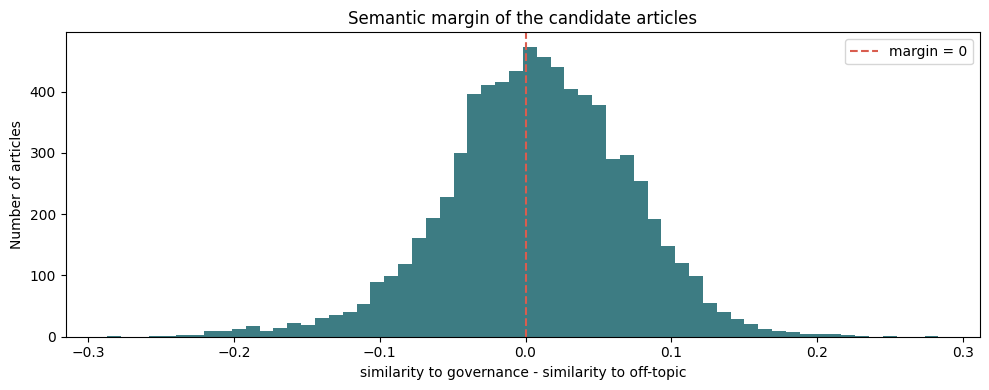


--- Q1 (lowest): margin -0.287 to -0.041 ---
-0.047  [industry_use   ] LumiQuant Academy Leads the Global Smart Trading Education Revolution with Quantyraxis AI, the 
-0.073  [market_report  ] OnlyFans in 2026: Is It Still Worth It for Gen Z Creators?
-0.195  [market_report  ] E-Learning Market Growth, Size, and Business Forecast 2026-2033
-0.046  [energy         ] New Smart Windows that are Self-Cleaning & Energy Efficient
-0.075  [industry_use   ] AI is Transforming Consumer Packaged Goods ( CPG): Are You Keeping Up?
-0.080  [market_report  ] Midyear update 2025 AI predictions: PwC
-0.062  [enterprise     ] Leona Health Raises $ 14M from a16z for WhatsApp AI Co-Pilot Aiding LatAm Doctors
-0.093  [market_report  ] KPMG Careers: Experienced Professionals

--- Q2: margin -0.040 to -0.007 ---
-0.033  [industry_use   ] Vendor Payment Automation
-0.026  [enterprise     ] Discussion with Professor Marina Jirotka, Human Centered Computing, University of Oxford
-0.011  [industry_use   ] Adva

gov_v2,False,True,All
in_stage1,,,
False,33759,1292,35051
True,9655,2738,12393
All,43414,4030,47444


In [8]:
cand = df[df["gov_lexical"]].copy()

# 1. Distribution of the semantic margin
plt.figure(figsize=(10, 4))
plt.hist(cand["sem_margin"], bins=60, color="#3D7C83")
plt.axvline(0, color="#D95D4F", linestyle="--", label="margin = 0")
plt.title("Semantic margin of the candidate articles")
plt.xlabel("similarity to governance - similarity to off-topic")
plt.ylabel("Number of articles")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Random titles per margin quintile (from "clearly off-topic" to "clearly governance")
cand["margin_bin"] = pd.qcut(cand["sem_margin"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
for bin_name, group in cand.groupby("margin_bin", observed=True):
    print(f"\n--- {bin_name}: margin {group['sem_margin'].min():.3f} to {group['sem_margin'].max():.3f} ---")
    for _, row in group.sample(n=8, random_state=RANDOM_STATE).iterrows():
        label = row["sem_gov_label"] if row["sem_margin"] > 0 else row["sem_off_label"]
        print(f"{row['sem_margin']:+.3f}  [{label:<15}] {str(row['title'])[:95]}")

# 3. Articles we discussed in the lexical step
CHECK_TITLES = ["Privacy notice", "Tesla Cybercab", "IoT on Manufacturing", "Laura Zommer",
                "SEO", "Copyright Office", "EU Fines Google", "AI safety amid Trump", "woke AI"]
print("\n--- Known examples ---")
for keyword in CHECK_TITLES:
    rows = cand[cand["title"].str.contains(keyword, regex=False, na=False)]
    for _, row in rows.head(2).iterrows():
        print(f"{row['sem_margin']:+.3f}  {str(row['title'])[:95]}")

# 4. Provisional combined filter: lexical candidate AND positive semantic margin
df["gov_v2"] = df["gov_lexical"] & (df["sem_margin"] > 0)
print(f"\nCandidates (lexical):      {df['gov_lexical'].sum():,}")
print(f"Lexical + semantic (> 0):  {df['gov_v2'].sum():,}")
display(pd.crosstab(df["in_stage1"], df["gov_v2"], margins=True))

### Results of the semantic score (Pascal)

The semantic margin separates the candidates roughly, but not sharply: its standard deviation is only 0.063. A random sample per quintile shows:

- **Q1–Q2 (margin below −0.007):** almost only off-topic articles, e.g. market reports, trading software, a KPMG careers page and healthcare applications. The *"Privacy notice"* page (−0.177) and the IoT manufacturing guide (−0.071) are correctly removed.
- **Q3 (around 0):** mixed. Funding rounds of compliance startups and articles about AGI or quantum partnerships appear next to real governance articles such as the DOJ antitrust case.
- **Q4–Q5:** mostly governance articles, e.g. caste bias in OpenAI models, the Reddit vs. Perplexity lawsuit, the Digital Markets Act, the US Copyright Office report and Trump's AI Action Plan.

With a threshold of 0, the combined filter keeps **4,030 articles**: 2,738 from the Stage 1 corpus and 1,292 new ones. Some false positives remain, e.g. *"Tesla Cybercab Prototypes Tested in Austin"* (+0.053) and articles about AI and SEO.

So far we set the threshold of 0 and the combination of the lexical and semantic scores by hand. In the next section we evaluate both on a manually annotated sample and choose the final filter based on measured precision and recall.

## 1.2 Evaluation of the topic filter (manual annotation)

To measure the quality of the filters, we need a gold standard. We annotate a **stratified random sample of 185 articles** from the full corpus.

**Strata.** A purely random sample would contain only about 15% candidates, and very few of the borderline cases. We therefore sample from eight strata:

| Stratum | Description | Sample |
|---|---|---:|
| C1–C5 | Lexical candidates, split into quintiles of the semantic margin | 5 × 25 |
| N1 | Not a candidate, but in the Stage 1 corpus (removed by the new filter) | 25 |
| N2 | Not a candidate, not in Stage 1, but at least one governance term | 25 |
| N3 | No governance term at all | 10 |

Strata N1–N3 tell us whether the candidate filter misses real governance articles (**recall**). Each stratum is later weighted by the inverse of its sampling rate. This way the metrics estimate the performance on the whole corpus, not only on the sample.

**Blind annotation.** The annotation file contains only the title, date, source, URL and the first 150 words, without stratum or scores. The articles are shuffled, so the annotators do not know which filter kept an article.

**Annotation guideline.**

- `1` = **AI Governance is the main subject** of the article: laws and regulation of AI, enforcement and fines, lawsuits about AI (copyright, liability), bias and fairness of AI systems, AI safety and AI security, transparency, accountability and oversight of AI, privacy and data protection in AI, policies against deepfakes and AI misinformation.
- `0` = AI Governance is **not** the main subject, even if it is mentioned: product launches, funding rounds, market reports, AI applications in industries, general cybersecurity, politics or energy without an AI-governance focus, website pages (privacy notices, profiles, careers).
- **Borderline rules:** Tech regulation **without an AI focus** (e.g. an antitrust fine about adtech) = `0`. An AI-governance product launch (e.g. "AI governance capabilities" of a software vendor) = `0`, because it is a product announcement. A political article whose main subject is an AI policy (e.g. Trump's AI Action Plan) = `1`.
- If unsure after reading the lead, open the URL. Write the reason for difficult cases in `notes`.

**Inter-annotator agreement.** One team member annotates all 185 articles (`label_A`). A second member independently annotates the 50 articles marked with `double_annotation = True` (`label_B`). We report Cohen's κ, and disagreements are discussed and resolved in `label_final`.

In [9]:
ANNOTATION_FILE = os.path.join(STAGE3_FOLDER, "annotation_sample.csv")
ANNOTATED_FILE  = os.path.join(STAGE3_FOLDER, "annotation_labeled.csv")

SAMPLE_SIZES = {"C1": 25, "C2": 25, "C3": 25, "C4": 25, "C5": 25, "N1": 25, "N2": 25, "N3": 10}
N_DOUBLE = 50
LEAD_WORDS_ANNOTATION = 150

# 1. Assign every article of the full corpus to one stratum
cand_mask = df["gov_lexical"]
df["stratum"] = "N3"
df.loc[~cand_mask & df["in_stage1"], "stratum"] = "N1"
df.loc[~cand_mask & ~df["in_stage1"] & (df["gov_score_per_1k"] > 0), "stratum"] = "N2"
df.loc[cand_mask, "stratum"] = pd.qcut(
    df.loc[cand_mask, "sem_margin"], 5, labels=["C1", "C2", "C3", "C4", "C5"]
).astype(str)

print("Articles per stratum in the full corpus:")
display(df["stratum"].value_counts().sort_index().rename("articles").to_frame())

# 2. Draw the sample (only once, so existing annotations are never overwritten)
if os.path.exists(ANNOTATION_FILE):
    print(f"Annotation sample already exists: {ANNOTATION_FILE}")
else:
    sample = pd.concat([
        df[df["stratum"] == stratum].sample(n=n, random_state=RANDOM_STATE)
        for stratum, n in SAMPLE_SIZES.items()
    ])
    # Shuffle, so that the order does not reveal the strata
    sample = sample.sample(frac=1, random_state=RANDOM_STATE)

    annotation = pd.DataFrame({
        "doc_id": sample.index,
        "title": sample["title"].values,
        "date": sample["published_at"].dt.strftime("%Y-%m-%d").values,
        "domain": sample["domain"].values,
        "url": sample["url"].values,
        "lead": [
            " ".join(re.sub(r"<[^>]+>", " ", str(c)).split()[:LEAD_WORDS_ANNOTATION])
            for c in sample["content"]
        ],
    })
    annotation["double_annotation"] = False
    annotation.loc[annotation.sample(n=N_DOUBLE, random_state=RANDOM_STATE).index, "double_annotation"] = True
    for col in ["label_A", "label_B", "label_final", "notes"]:
        annotation[col] = ""

    annotation.to_csv(ANNOTATION_FILE, index=False)
    print(f"Saved {len(annotation)} articles for annotation: {ANNOTATION_FILE}")

Articles per stratum in the full corpus:


,articles
stratum,
C1,1453
C2,1453
C3,1452
C4,1453
C5,1453
N1,7433
N2,17453
N3,15294


Saved 185 articles for annotation: /content/drive/MyDrive/CTA-media-analysis/stage3/annotation_sample.csv


# To Do: Annotations. Discuss at next meeting!